# 03 – WAR Model (v0.2)

**What changed from v0.1:**

| Change | Why |
|---|---|
| **+ Power play offense** | Stars like McDavid and MacKinnon play 300+ PP minutes; v0.1 ignored all of it |
| **+ Penalty kill defense** | Same idea for shorthanded minutes |
| **+ Finishing (half credit)** | Elite shooters score more than their expected goals; v0.1 gave zero credit for that |
| **+ Faceoffs (centers)** | Small but real value |
| **Defense counted at half weight** | The on-ice defense measurement is noisy: it partly reflects linemates and competition, not just the player. Less reliable → less weight. |

v0.1 stays untouched in `02_war_model.ipynb`, so the two versions can be compared (section 11).

Requires: notebooks 01 and 02 have been run.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA = Path("../data")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

## 2. Load data
Same starting point as v0.1: the clean table from notebook 01, plus even-strength bench time and off-ice xG against from the raw file.

In [2]:
players = pd.read_csv(DATA / "skaters_clean.csv")
replacement_01 = pd.read_csv(DATA / "replacement_rates.csv", index_col=0)
raw = pd.read_csv(DATA / "skaters25-26.csv")

extra = (raw.loc[raw["situation"] == "5on5", ["playerId", "timeOnBench", "OffIce_A_xGoals"]]
            .rename(columns={"timeOnBench": "ev_bench_sec", "OffIce_A_xGoals": "ev_OffIce_A_xGoals"}))
players = players.merge(extra, on="playerId", how="left")
players["ev_bench_toi"] = players["ev_bench_sec"] / 60

print(players.shape)

(940, 76)


## 3. Model assumptions
Three new constants on top of v0.1's.

| Constant | Value | Why |
|---|---|---|
| `GOALS_PER_WIN` | 6.0 | ~6 goals of goal differential ≈ 1 win |
| `PENALTY_GOAL_VALUE` | 0.17 | A power play is worth roughly 0.15–0.2 goals |
| `A1_WEIGHT` | 0.5 | Half credit for a primary assist |
| **`FINISH_WEIGHT`** | 0.5 | Finishing is real but noisy year to year, so it gets half credit |
| **`DEF_WEIGHT`** | 0.5 | On-ice defense is the least reliable measurement in the model, so it gets half weight |
| **`FO_GOAL_VALUE`** | 0.015 | A single faceoff win is worth roughly 0.01–0.02 goals on average |

In [3]:
GOALS_PER_WIN = 6.0
PENALTY_GOAL_VALUE = 0.17
A1_WEIGHT = 0.5
FINISH_WEIGHT = 0.5
DEF_WEIGHT = 0.5
FO_GOAL_VALUE = 0.015

## 4. Helper functions
Three small functions used throughout, so the math is written once:
- `rate60`: per-60 rate, blank if no ice time
- `pooled`: total stat ÷ total minutes for a group (same pooling idea as notebook 01)
- `repl`: looks up the right replacement number for each player's position group

In [4]:
def rate60(count, toi):
    return np.where(toi > 0, count / toi * 60, np.nan)

def pooled(group, stat, toi_col):
    return group[stat].sum() / group[toi_col].sum() * 60

def repl(table, col):
    """Replacement value for each player's position group (F or D)."""
    return players["pos_group"].map(table[col])

## 5. Replacement levels
Each part of the game gets its own replacement pool:

| Situation | Regulars | Replacement pool |
|---|---|---|
| Even strength | Top 13 F / 7 D per team by ice time (from notebook 01) | Everyone else with 100+ EV minutes |
| Power play | Top 10 per team by PP time (two units) | Everyone else with 10+ PP minutes |
| Penalty kill | n/a | **League-average penalty killer** (see note) |
| Faceoffs | Regular centers | Non-regular centers with 100+ faceoffs |

**Even-strength defense** is the same as v0.1: team xG allowed per 60 on the **bench** minus on the **ice**.

**Penalty kill is handled differently**, because the v0.1 method broke here. When I first built this, elite penalty killers like Jaccob Slavin and Esa Lindell came out *below replacement level*. Two reasons:
1. **Bench comparison is unfair on the PK.** Top killers take the hardest shifts (start of the penalty, against the other team's best power play unit). When they're on the bench, it's often the easier tail end of the penalty.
2. **Fringe killers get easy minutes**, so the "replacement" group actually looked *better* than the regulars.

The fix: compare each player's on-ice PK xG against to **his team's overall PK rate**, and use the **league-average penalty killer** as the baseline instead of a replacement pool. This is a documented compromise.

In [5]:
# --- Even strength ---
players["ev_rel_xga_60"] = (rate60(players["ev_OffIce_A_xGoals"], players["ev_bench_toi"])
                            - rate60(players["ev_OnIce_A_xGoals"], players["ev_toi"]))
players["ev_rel_xga_60"] = players["ev_rel_xga_60"].fillna(0)

ev_pool = players[(~players["is_regular"]) & (players["ev_toi"] >= 100)]
ev_repl = replacement_01.copy()
ev_repl["fin_60"] = ev_repl["goals_60"] - ev_repl["ixg_60"]
ev_repl = ev_repl.join(ev_pool.groupby("pos_group").apply(lambda g: pd.Series({
    "rel_xga_60": (g["ev_rel_xga_60"] * g["ev_toi"]).sum() / g["ev_toi"].sum(),
    "pen_diff_60": g["pen_diff"].sum() / g["all_toi"].sum() * 60,
}), include_groups=False))

# --- Power play ---
players["pp_rank"] = players.groupby("team")["pp_toi"].rank(ascending=False, method="first")
pp_pool = players[(players["pp_rank"] > 10) & (players["pp_toi"] >= 10)]
pp_repl = pp_pool.groupby("pos_group").apply(lambda g: pd.Series({
    "ixg_60": pooled(g, "pp_I_F_xGoals", "pp_toi"),
    "fin_60": pooled(g, "pp_I_F_goals", "pp_toi") - pooled(g, "pp_I_F_xGoals", "pp_toi"),
    "a1_60":  pooled(g, "pp_I_F_primaryAssists", "pp_toi"),
}), include_groups=False)

# --- Penalty kill: team-relative, league-average baseline ---
team_pk_xga_60 = players.groupby("team").apply(
    lambda g: g["pk_OnIce_A_xGoals"].sum() / g["pk_toi"].sum() * 60, include_groups=False)
players["pk_rel_xga_60"] = (players["team"].map(team_pk_xga_60)
                            - rate60(players["pk_OnIce_A_xGoals"], players["pk_toi"]))
players["pk_rel_xga_60"] = players["pk_rel_xga_60"].fillna(0)
pk_pool = players[players["pk_toi"] >= 10]   # all penalty killers -> league average
pk_repl = pk_pool.groupby("pos_group").apply(lambda g: pd.Series({
    "rel_xga_60": (g["pk_rel_xga_60"] * g["pk_toi"]).sum() / g["pk_toi"].sum(),
}), include_groups=False)

# --- Faceoffs ---
players["fo_total"] = players["all_faceoffsWon"] + players["all_faceoffsLost"]
fo_pool = players[(players["position"] == "C") & (~players["is_regular"]) & (players["fo_total"] >= 100)]
FO_REPL_PCT = fo_pool["all_faceoffsWon"].sum() / fo_pool["fo_total"].sum()

print("Pool sizes  EV:", ev_pool.groupby("pos_group").size().to_dict(),
      "| PP:", pp_pool.groupby("pos_group").size().to_dict(),
      "| PK (all killers):", pk_pool.groupby("pos_group").size().to_dict(),
      "| FO centers:", len(fo_pool))
print(f"Replacement faceoff %: {FO_REPL_PCT:.3f}")
print()
print("Even strength replacement:"); print(ev_repl.round(3)); print()
print("Power play replacement:");    print(pp_repl.round(3)); print()
print("Penalty kill baseline (league average):");  print(pk_repl.round(3))

Pool sizes  EV: {'D': 46, 'F': 95} | PP: {'D': 48, 'F': 114} | PK (all killers): {'D': 224, 'F': 273} | FO centers: 22
Replacement faceoff %: 0.505

Even strength replacement:
           goals_60  a1_60  ixg_60  xgf_60  xga_60  fin_60  rel_xga_60  pen_diff_60
pos_group                                                                          
D             0.129  0.226   0.145   2.404   2.478  -0.016       0.007       -0.385
F             0.529  0.359   0.666   2.228   2.382  -0.136       0.120       -0.059

Power play replacement:
           ixg_60  fin_60  a1_60
pos_group                       
D           0.478  -0.156  1.217
F           1.403  -0.339  0.863

Penalty kill baseline (league average):
           rel_xga_60
pos_group            
D               0.007
F              -0.043


## 6. Offense: even strength + power play
Same formula for both situations, now with finishing:

`GAR = (xG − replacement xG) + 0.5 × (finishing − replacement finishing) + 0.5 × (primary assists − replacement A1)`

where **finishing = goals − expected goals**, and every replacement number is scaled to the player's own minutes.

In [6]:
def offense_gar(prefix, repl_table):
    hours = players[f"{prefix}_toi"] / 60
    xg, goals, a1 = (players[f"{prefix}_I_F_xGoals"], players[f"{prefix}_I_F_goals"],
                     players[f"{prefix}_I_F_primaryAssists"])
    return ((xg - repl(repl_table, "ixg_60") * hours)
            + FINISH_WEIGHT * ((goals - xg) - repl(repl_table, "fin_60") * hours)
            + A1_WEIGHT * (a1 - repl(repl_table, "a1_60") * hours))

players["ev_off_gar"] = offense_gar("ev", ev_repl)
players["pp_off_gar"] = offense_gar("pp", pp_repl)

players.sort_values("pp_off_gar", ascending=False)[["name", "team", "pp_toi", "pp_I_F_goals", "pp_off_gar"]].head(10).round(2)

,name,team,pp_toi,pp_I_F_goals,pp_off_gar
136,Wyatt Johnston,DAL,273.23,23.0,15.02
862,Connor McDavid,EDM,283.03,12.0,14.87
596,Leon Draisaitl,EDM,225.42,16.0,14.09
227,Jake DeBrusk,VAN,231.00,19.0,12.55
857,Mika Zibanejad,NYR,252.53,16.0,12.01
737,Pavel Dorofeyev,VGK,269.70,19.0,11.97
433,Sam Reinhart,FLA,254.45,10.0,9.98
658,Mark Stone,VGK,197.32,9.0,9.94
506,Kirill Kaprizov,MIN,291.13,15.0,8.68
933,Cole Caufield,MTL,259.35,10.0,8.60


## 7. Defense: even strength + penalty kill (half weight)

In [7]:
players["ev_def_gar"] = DEF_WEIGHT * (players["ev_rel_xga_60"] - repl(ev_repl, "rel_xga_60")) * players["ev_toi"] / 60
players["pk_def_gar"] = DEF_WEIGHT * (players["pk_rel_xga_60"] - repl(pk_repl, "rel_xga_60")) * players["pk_toi"] / 60

players.sort_values("pk_def_gar", ascending=False)[["name", "team", "position", "pk_toi", "pk_def_gar"]].head(10).round(2)

,name,team,position,pk_toi,pk_def_gar
813,Connor Murphy,EDM,D,208.97,2.97
774,Jason Dickinson,EDM,C,129.45,2.86
187,Brock Nelson,COL,C,140.55,2.64
99,Noah Cates,PHI,L,135.17,2.43
898,Collin Graf,SJS,R,195.55,2.42
862,Connor McDavid,EDM,C,83.30,2.07
901,Noah Dobson,MTL,D,155.57,2.05
345,Ilya Mikheyev,CHI,R,190.47,2.04
799,Vincent Desharnais,SJS,D,165.52,1.98
776,Erik Karlsson,PIT,D,136.65,1.94


## 8. Penalties and faceoffs

In [8]:
players["pen_gar"] = PENALTY_GOAL_VALUE * (players["pen_diff"] - repl(ev_repl, "pen_diff_60") * players["all_toi"] / 60)

players["fo_gar"] = np.where(players["position"] == "C",
                             FO_GOAL_VALUE * (players["all_faceoffsWon"] - FO_REPL_PCT * players["fo_total"]),
                             0.0)

players.sort_values("fo_gar", ascending=False)[["name", "team", "fo_total", "fo_pct", "fo_gar"]].head(5).round(3)

,name,team,fo_total,fo_pct,fo_gar
508,Jonathan Toews,WPG,1026.0,0.621,1.790
619,Dylan Strome,WSH,1334.0,0.582,1.558
649,John Tavares,TOR,1392.0,0.575,1.479
198,J.T. Miller,NYR,890.0,0.615,1.469
431,Nico Hischier,NJD,1808.0,0.558,1.436


## 9. Total WAR and leaderboard

In [9]:
COMPONENTS = ["ev_off_gar", "pp_off_gar", "ev_def_gar", "pk_def_gar", "pen_gar", "fo_gar"]

players["gar"] = players[COMPONENTS].sum(axis=1)
players["war"] = players["gar"] / GOALS_PER_WIN
players["war_rank"] = players["war"].rank(ascending=False, method="min").astype(int)

leaders = (players.sort_values("war", ascending=False)
                  [["name", "team", "position"] + COMPONENTS + ["war"]]
                  .head(20).reset_index(drop=True))
leaders.index = leaders.index + 1
leaders.round(2)

,name,team,position,ev_off_gar,pp_off_gar,ev_def_gar,pk_def_gar,pen_gar,fo_gar,war
1,Connor McDavid,EDM,C,14.49,14.87,-4.51,2.07,5.58,-0.13,5.40
2,Cole Caufield,MTL,R,16.51,8.60,0.88,0.03,1.77,0.00,4.63
3,Nathan MacKinnon,COL,C,22.98,6.89,-6.36,0.14,1.49,0.12,4.21
4,Leon Draisaitl,EDM,C,9.27,14.09,-0.89,1.18,-0.11,1.07,4.10
5,David Pastrnak,BOS,R,15.53,8.46,-1.60,0.14,1.28,0.00,3.97
6,Mark Stone,VGK,R,7.74,9.94,0.85,0.62,2.40,0.00,3.59
7,Mika Zibanejad,NYR,C,6.70,12.01,0.87,0.72,0.62,0.33,3.54
8,Macklin Celebrini,SJS,C,16.15,5.13,-2.47,0.09,1.99,-0.35,3.42
9,Nikita Kucherov,TBL,R,17.90,6.77,-5.45,-0.20,1.45,0.00,3.41
10,Rasmus Dahlin,BUF,D,12.59,3.16,2.92,0.98,0.67,0.00,3.39


In [10]:
for grp, label in [("F", "Forwards"), ("D", "Defensemen")]:
    print(label)
    print(players[players["pos_group"] == grp]
          .sort_values("war", ascending=False)[["name", "team", "war"]]
          .head(5).round(2).to_string(index=False))
    print()
print("Defensemen in the top 20:", (players.nsmallest(20, "war_rank")["pos_group"] == "D").sum())

Forwards
            name team  war
  Connor McDavid  EDM 5.40
   Cole Caufield  MTL 4.63
Nathan MacKinnon  COL 4.21
  Leon Draisaitl  EDM 4.10
  David Pastrnak  BOS 3.97

Defensemen
         name team  war
Rasmus Dahlin  BUF 3.39
   Cale Makar  COL 3.22
  Lane Hutson  MTL 3.17
Zach Werenski  CBJ 3.17
Evan Bouchard  EDM 2.82

Defensemen in the top 20: 4


## 10. Chart: what drives the top 15 (v0.2)

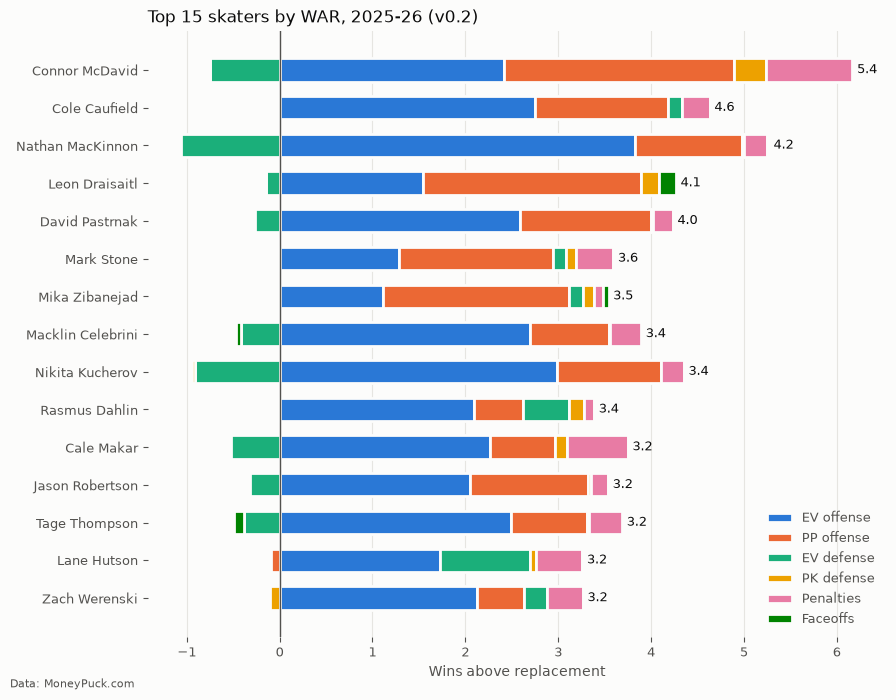

In [11]:
COLORS = {"ev_off_gar": "#2a78d6", "pp_off_gar": "#eb6834", "ev_def_gar": "#1baf7a",
          "pk_def_gar": "#eda100", "pen_gar": "#e87ba4", "fo_gar": "#008300"}
LABELS = {"ev_off_gar": "EV offense", "pp_off_gar": "PP offense", "ev_def_gar": "EV defense",
          "pk_def_gar": "PK defense", "pen_gar": "Penalties", "fo_gar": "Faceoffs"}
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"

def component_chart(df, title, path):
    top = df.sort_values("war", ascending=False).head(15).iloc[::-1]
    comp = top[list(COLORS)] / GOALS_PER_WIN
    fig, ax = plt.subplots(figsize=(9, 7), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    pos_left, neg_left = np.zeros(len(top)), np.zeros(len(top))
    for col, color in COLORS.items():
        vals = comp[col].to_numpy()
        ax.barh(top["name"], vals, left=np.where(vals >= 0, pos_left, neg_left), color=color,
                height=0.62, edgecolor=SURFACE, linewidth=2, label=LABELS[col])
        pos_left += np.where(vals >= 0, vals, 0)
        neg_left += np.where(vals < 0, vals, 0)
    for y, (total, end) in enumerate(zip(top["war"], pos_left)):
        ax.text(end + 0.05, y, f"{total:.1f}", va="center", fontsize=9, color=INK)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_xlabel("Wins above replacement", color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=MUTED)
    fig.text(0.01, 0.01, "Data: MoneyPuck.com", fontsize=8, color=MUTED)
    plt.tight_layout()
    fig.savefig(path, dpi=150, facecolor=SURFACE)
    plt.show()

component_chart(players, "Top 15 skaters by WAR, 2025-26 (v0.2)", IMAGES / "war_top15_v02.png")

## 11. Version comparison: v0.1 vs v0.2
Tracking how the model changes between versions shows whether each change moved the results in a sensible direction.

**Spearman rank correlation** measures how similar two rankings are: 1.0 = identical order, 0 = no relationship. A value well below 1 means the new version reshuffled the rankings a lot, which we'd expect when adding whole new parts of the game.

In [12]:
v01 = pd.read_csv(DATA / "war_v01.csv")[["playerId", "war"]].rename(columns={"war": "war_v01"})

history = (players[["playerId", "name", "team", "position", "pos_group", "ev_toi", "war"]]
             .rename(columns={"war": "war_v02"})
             .merge(v01, on="playerId", how="left"))
history["rank_v01"] = history["war_v01"].rank(ascending=False, method="min").astype(int)
history["rank_v02"] = history["war_v02"].rank(ascending=False, method="min").astype(int)
history["rank_change"] = history["rank_v01"] - history["rank_v02"]   # positive = moved up

corr = history["war_v01"].corr(history["war_v02"], method="spearman")
print(f"Spearman rank correlation, v0.1 vs v0.2: {corr:.2f}")

regulars = history[history["ev_toi"] >= 500]
show = ["name", "team", "position", "rank_v01", "rank_v02", "rank_change", "war_v01", "war_v02"]
print("\nBiggest risers (500+ EV minutes):")
print(regulars.sort_values("rank_change", ascending=False)[show].head(8).round(2).to_string(index=False))
print("\nBiggest fallers (500+ EV minutes):")
print(regulars.sort_values("rank_change")[show].head(8).round(2).to_string(index=False))

Spearman rank correlation, v0.1 vs v0.2: 0.72

Biggest risers (500+ EV minutes):
             name team position  rank_v01  rank_v02  rank_change  war_v01  war_v02
   Wyatt Johnston  DAL        C       924        50          874    -1.47     2.19
    Brad Marchand  FLA        L       923       197          726    -1.47     0.87
Andrei Svechnikov  CAR        R       834       112          722    -0.63     1.41
    Connor Bedard  CHI        C       822       105          717    -0.57     1.46
       Bryan Rust  PIT        R       797        81          716    -0.46     1.71
      Pavel Zacha  BOS        C       829       116          713    -0.60     1.37
    Sidney Crosby  PIT        C       766        56          710    -0.39     2.06
  Juraj Slafkovsk  MTL        L       788        89          699    -0.44     1.65

Biggest fallers (500+ EV minutes):
             name team position  rank_v01  rank_v02  rank_change  war_v01  war_v02
   Connor Clifton  PIT        D       211       844  

### Rank change chart
For the v0.2 top 15: the gray dot is where each player ranked in v0.1, the blue dot is v0.2. The rank axis uses a log scale so the jump from #256 to #9 and the jump from #3 to #1 both fit.

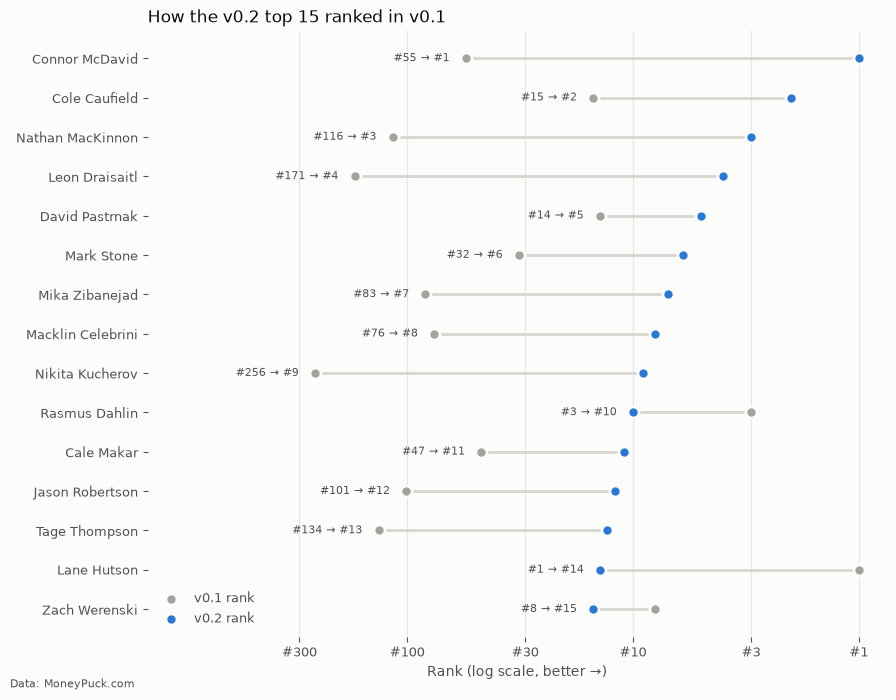

In [13]:
top = history.sort_values("rank_v02").head(15).iloc[::-1]
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(9, 7), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.hlines(y, top["rank_v02"], top["rank_v01"], color="#d6d5d0", linewidth=2, zorder=1)
ax.scatter(top["rank_v01"], y, s=64, color="#a3a29c", edgecolor=SURFACE, linewidth=2, zorder=2, label="v0.1 rank")
ax.scatter(top["rank_v02"], y, s=64, color="#2a78d6", edgecolor=SURFACE, linewidth=2, zorder=3, label="v0.2 rank")
for yi, (r1, r2) in enumerate(zip(top["rank_v01"], top["rank_v02"])):
    ax.text(max(r1, r2) * 1.18, yi, f"#{r1} → #{r2}", va="center", ha="right", fontsize=8, color=MUTED)

ax.set_yticks(y)
ax.set_yticklabels(top["name"])
ax.set_xscale("log")
ax.set_xlim(right=history["rank_v01"].max() * 1.5)
ax.invert_xaxis()   # #1 on the right
ax.set_xticks([1, 3, 10, 30, 100, 300])
ax.set_xticklabels(["#1", "#3", "#10", "#30", "#100", "#300"])
ax.minorticks_off()
ax.set_xlabel("Rank (log scale, better →)", color=MUTED)
ax.set_title("How the v0.2 top 15 ranked in v0.1", loc="left", color=INK, fontsize=12)
ax.tick_params(colors=MUTED, labelsize=9)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=MUTED)
fig.text(0.01, 0.01, "Data: MoneyPuck.com", fontsize=8, color=MUTED)
plt.tight_layout()
fig.savefig(IMAGES / "rank_change_v01_v02.png", dpi=150, facecolor=SURFACE)
plt.show()

## 12. Sanity check: the superstars again

In [14]:
STARS = ["Connor McDavid", "Nathan MacKinnon", "Nikita Kucherov", "Leon Draisaitl",
         "Auston Matthews", "Cale Makar", "Quinn Hughes", "David Pastrnak", "Lane Hutson"]

history[history["name"].isin(STARS)][["name", "team", "rank_v01", "rank_v02", "war_v01", "war_v02"]].sort_values("rank_v02").round(2)

,name,team,rank_v01,rank_v02,war_v01,war_v02
862,Connor McDavid,EDM,55,1,1.30,5.40
547,Nathan MacKinnon,COL,116,3,0.87,4.21
596,Leon Draisaitl,EDM,171,4,0.62,4.10
930,David Pastrnak,BOS,14,5,1.94,3.97
65,Nikita Kucherov,TBL,256,9,0.38,3.41
822,Cale Makar,COL,47,11,1.36,3.22
462,Lane Hutson,MTL,1,14,4.09,3.17
417,Quinn Hughes,MIN,13,40,1.96,2.42
834,Auston Matthews,TOR,162,63,0.64,1.97


**Question for you:** Lane Hutson was #1 in v0.1. Where did he land in v0.2, and which specific changes caused the move? Use the leaderboard components in section 9 to back up your answer.

## 13. Save
- `war_v02.csv`: full v0.2 results
- `war_history.csv`: one row per player with every version's WAR and rank. Future versions add their own columns here, so the model's progress is tracked over time.

In [15]:
players.to_csv(DATA / "war_v02.csv", index=False)
history.to_csv(DATA / "war_history.csv", index=False)
print("Saved war_v02.csv and war_history.csv")

Saved war_v02.csv and war_history.csv


## Known limitations (v0.2)
- **Defense is still the weakest piece**: half weight reduces the noise but doesn't remove the competition and linemate effects
- **Shutdown defensemen are undervalued**: low offense plus half-weight defense pushes players like Slavin and Forsling toward replacement level. Public models struggle with this too, but it's a real gap
- **Penalty kill uses a league-average baseline**, not replacement, so PK value is slightly understated
- **No adjustment for quality of competition or zone starts**
- **Constants are approximations** (goals per win, penalty value, faceoff value, assist and finishing weights)
- **Goalies are not included**
- **Traded players** are listed under one team

## Next
- Compare the leaderboard to a public WAR model
- Start on the roadmap: **aging curves**